# Netflix Content Analysis


In [16]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
os.makedirs("outputs", exist_ok=True)

## 1.	Dataset Overview

In [17]:
df = pd.read_csv("netflix_titles.csv")
print("Shape:", df.shape)
df.head()

Shape: (8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [18]:
df.info()
print()
print("Missing values per column:")
print(df.isna().sum())
print()
print("Duplicate rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB

Missing values per column:
show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in     

## 2. 	Data Preprocessing


In [19]:
clean = df.copy()


for col in clean.select_dtypes(include="object").columns:
    clean[col] = clean[col].str.strip()


clean = clean.drop_duplicates()


bad = clean["rating"].astype(str).str.contains("min", na=False)
print("Rows with duration in rating column:", bad.sum())
clean.loc[bad & clean["duration"].isna(), "duration"] = clean.loc[bad, "rating"]
clean.loc[bad, "rating"] = np.nan


for col in ["director", "cast", "country"]:
    clean[col] = clean[col].fillna("Unknown")
clean["rating"] = clean["rating"].fillna("Not Rated")


clean["date_added"] = pd.to_datetime(clean["date_added"], errors="coerce")
clean["year_added"] = clean["date_added"].dt.year
clean["month_added"] = clean["date_added"].dt.month


dur = clean["duration"].str.extract(r"(\d+)\s*(\w+)")
clean["duration_value"] = pd.to_numeric(dur[0], errors="coerce")
clean["duration_unit"] = dur[1]
clean["movie_minutes"] = np.where(clean["type"] == "Movie", clean["duration_value"], np.nan)
clean["tv_seasons"] = np.where(clean["type"] == "TV Show", clean["duration_value"], np.nan)


rating_map = {
    "G": "Kids", "TV-Y": "Kids", "TV-G": "Kids", "TV-Y7": "Kids", "TV-Y7-FV": "Kids", "PG": "Kids",
    "TV-PG": "Teens", "PG-13": "Teens", "TV-14": "Teens",
    "R": "Adults", "TV-MA": "Adults", "NC-17": "Adults",
}
clean["audience"] = clean["rating"].map(rating_map).fillna("Not Rated")

print("Cleaned shape:", clean.shape)
print(clean.isna().sum()[clean.isna().sum() > 0])
clean.head()

Rows with duration in rating column: 3
Cleaned shape: (8807, 19)
date_added         10
year_added         10
month_added        10
movie_minutes    2676
tv_seasons       6131
dtype: int64


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,year_added,month_added,duration_value,duration_unit,movie_minutes,tv_seasons,audience
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",2021.0,9.0,90,min,90.0,NaN,Teens
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",2021.0,9.0,2,Seasons,NaN,2.0,Adults
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,2021.0,9.0,1,Season,NaN,1.0,Adults
3,s4,TV Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",2021.0,9.0,1,Season,NaN,1.0,Adults
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,2021.0,9.0,2,Seasons,NaN,2.0,Adults


In [20]:
def explode_col(frame, col):
    out = frame[["show_id", "type", "release_year", "year_added", col]].copy()
    out[col] = out[col].str.split(",")
    out = out.explode(col)
    out[col] = out[col].str.strip()
    return out.reset_index(drop=True)

countries = explode_col(clean, "country")
countries = countries[countries["country"] != "Unknown"]

genres = explode_col(clean, "listed_in").rename(columns={"listed_in": "genre"})

directors = explode_col(clean, "director")
directors = directors[directors["director"] != "Unknown"]

clean.to_csv("outputs/netflix_cleaned.csv", index=False)
print("Countries rows:", len(countries), "| Genre rows:", len(genres), "| Director rows:", len(directors))

Countries rows: 10019 | Genre rows: 19323 | Director rows: 6978


## 3. Exploratory data analysis

### 3.1Movies and TV Shows

type
Movie      6131
TV Show    2676
Name: count, dtype: int64
type
Movie      69.6
TV Show    30.4
Name: count, dtype: float64


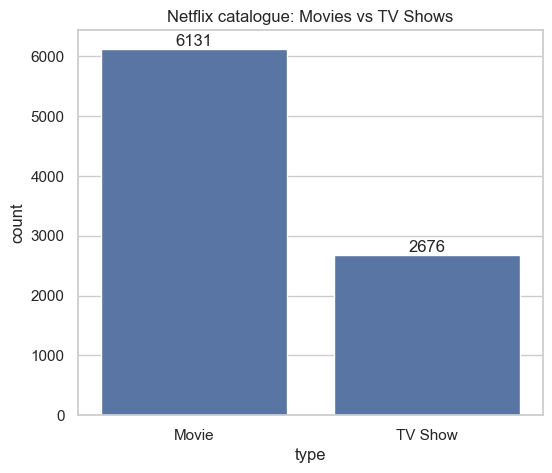

In [21]:
type_counts = clean["type"].value_counts()
print(type_counts)
print((type_counts / type_counts.sum() * 100).round(1))

fig, ax = plt.subplots(figsize=(6, 5))
sns.countplot(data=clean, x="type", ax=ax)
ax.set_title("Netflix catalogue: Movies vs TV Shows")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.savefig("outputs/01_type_split.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.2 Analysis by Release Year 

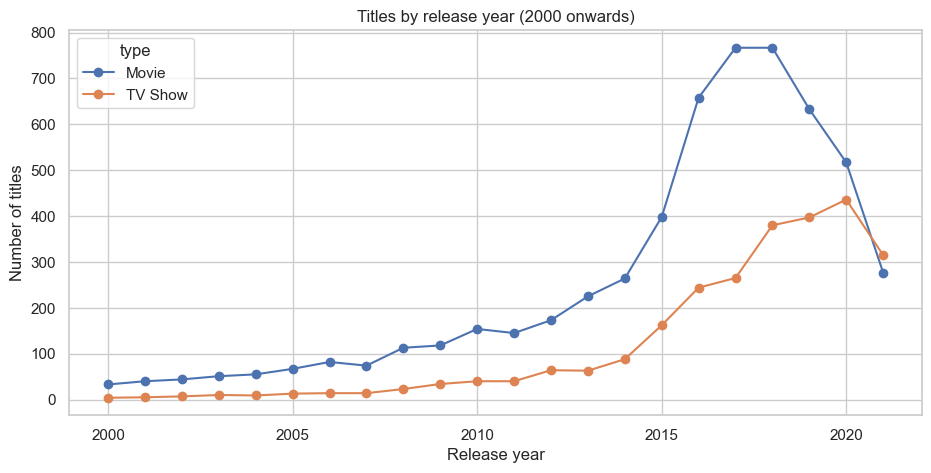

In [22]:
by_year = clean[clean["release_year"] >= 2000].groupby(["release_year", "type"]).size().unstack(fill_value=0)
by_year.plot(figsize=(11, 5), marker="o")
plt.title("Titles by release year (2000 onwards)")
plt.xlabel("Release year")
plt.ylabel("Number of titles")
plt.savefig("outputs/02_release_year_trend.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.3 Netflix Content Growth

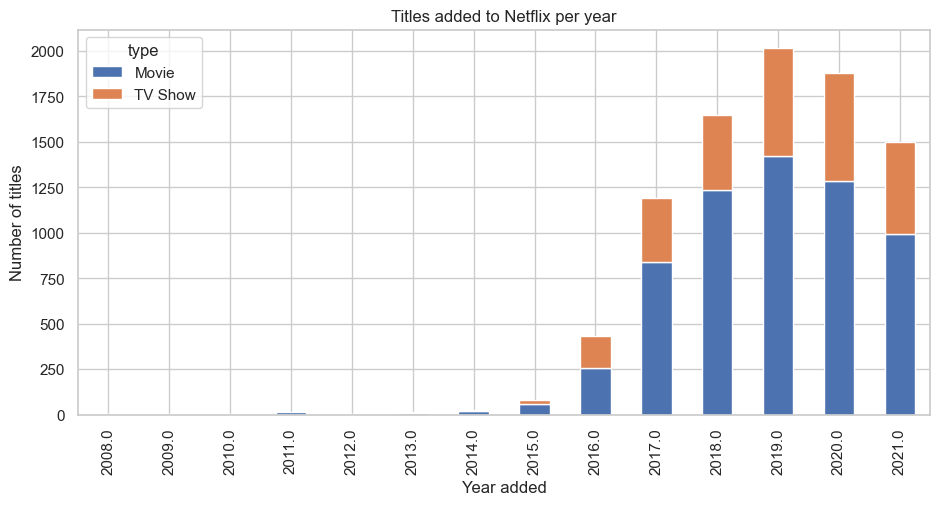

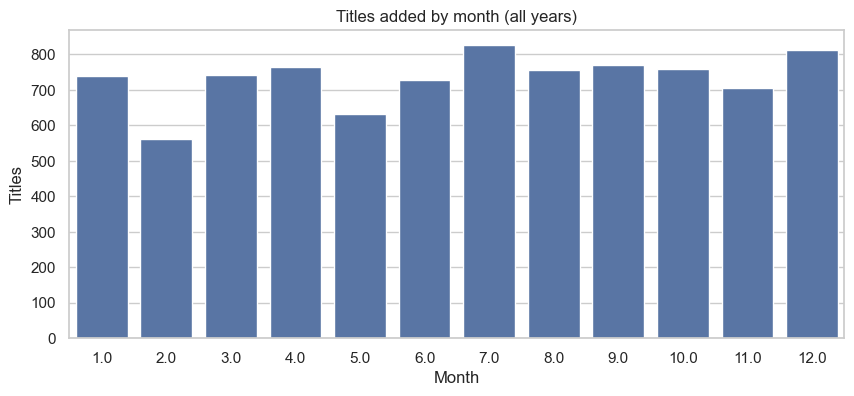

In [23]:
added = clean.dropna(subset=["year_added"]).groupby(["year_added", "type"]).size().unstack(fill_value=0)
added.plot(kind="bar", stacked=True, figsize=(11, 5))
plt.title("Titles added to Netflix per year")
plt.xlabel("Year added")
plt.ylabel("Number of titles")
plt.savefig("outputs/03_added_per_year.png", dpi=150, bbox_inches="tight")
plt.show()

month_counts = clean["month_added"].value_counts().sort_index()
plt.figure(figsize=(10, 4))
sns.barplot(x=month_counts.index, y=month_counts.values)
plt.title("Titles added by month (all years)")
plt.xlabel("Month")
plt.ylabel("Titles")
plt.savefig("outputs/04_added_by_month.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.4 Country-wise Analysis

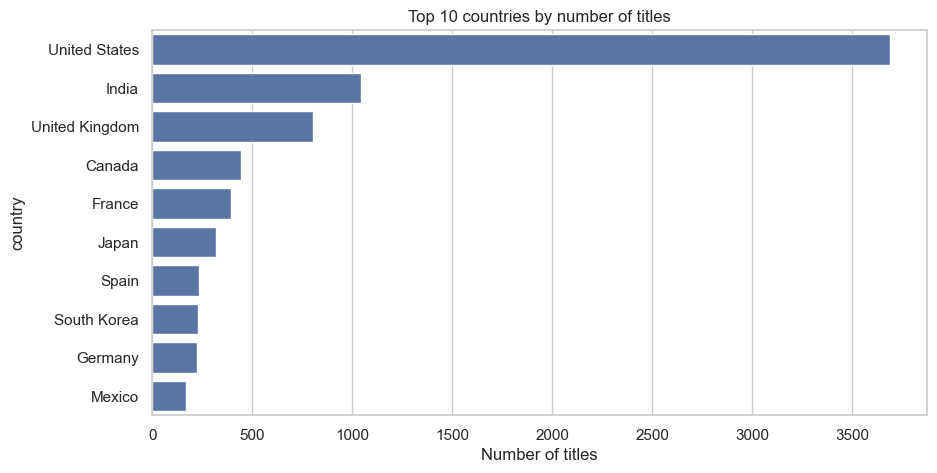

type,Movie,TV Show
country,,
Canada,0.72,0.28
France,0.77,0.23
India,0.92,0.08
United Kingdom,0.66,0.34
United States,0.75,0.25


In [24]:
top_countries = countries["country"].value_counts().head(10)
plt.figure(figsize=(10, 5))
sns.barplot(x=top_countries.values, y=top_countries.index)
plt.title("Top 10 countries by number of titles")
plt.xlabel("Number of titles")
plt.savefig("outputs/05_top_countries.png", dpi=150, bbox_inches="tight")
plt.show()

top5 = top_countries.index[:5]
pd.crosstab(countries[countries["country"].isin(top5)]["country"],
            countries[countries["country"].isin(top5)]["type"], normalize="index").round(2)

### 3.5 Content Ratings Analysis

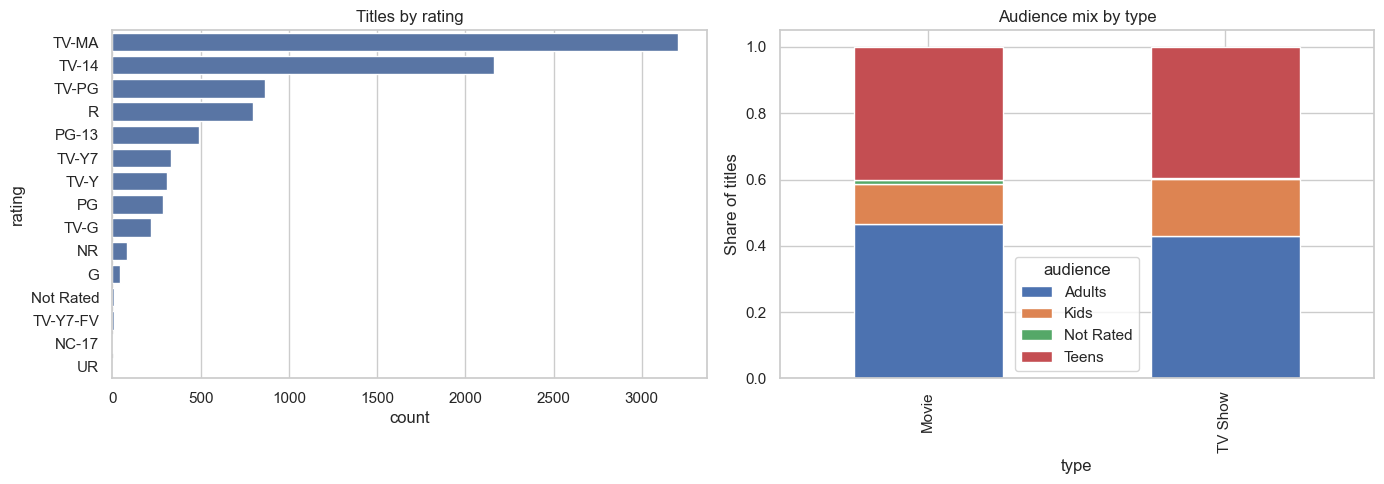

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
order = clean["rating"].value_counts().index
sns.countplot(data=clean, y="rating", order=order, ax=axes[0])
axes[0].set_title("Titles by rating")

aud = pd.crosstab(clean["type"], clean["audience"], normalize="index")
aud.plot(kind="bar", stacked=True, ax=axes[1])
axes[1].set_title("Audience mix by type")
axes[1].set_ylabel("Share of titles")
plt.tight_layout()
plt.savefig("outputs/06_ratings_audience.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.6 Genre-wise Analysis

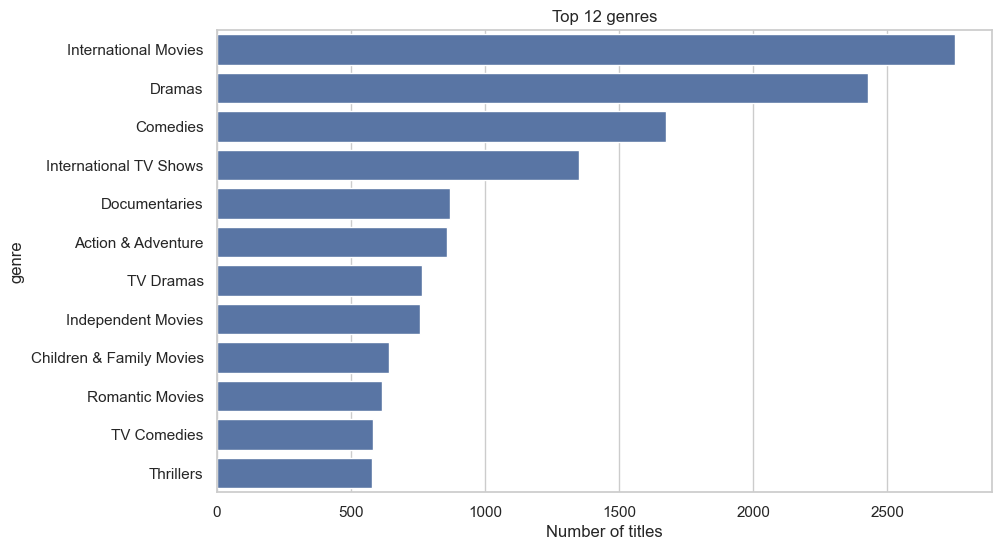

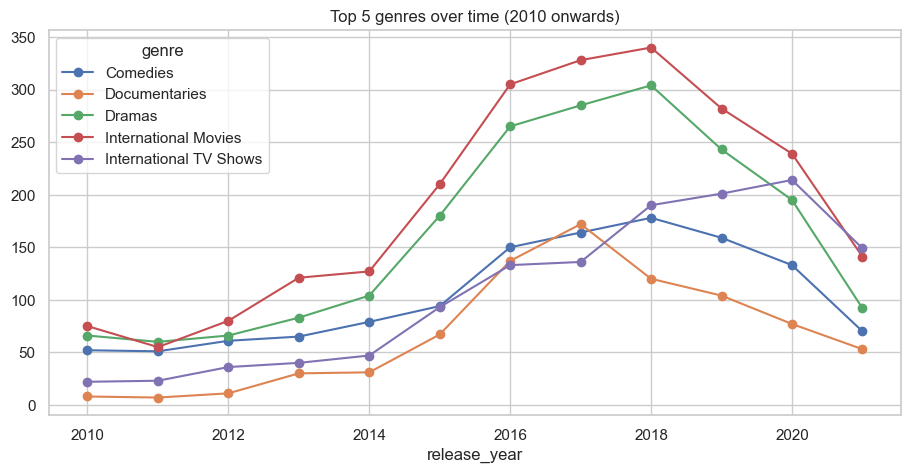

In [ ]:
top_genres = genres["genre"].value_counts().head(12)
plt.figure(figsize=(10, 6))
sns.barplot(x=top_genres.values, y=top_genres.index)
plt.title("Top 12 genres")
plt.xlabel("Number of titles")
plt.savefig("outputs/07_top_genres.png", dpi=150, bbox_inches="tight")
plt.show()


top5_genres = top_genres.index[:5]
gt = genres[genres["genre"].isin(top5_genres) & (genres["release_year"] >= 2010)]
gt.groupby(["release_year", "genre"]).size().unstack(fill_value=0).plot(figsize=(11, 5), marker="o")
plt.title("Top 5 genres over time (2010 onwards)")
plt.savefig("outputs/08_genre_trend.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.7 Director  Analysis

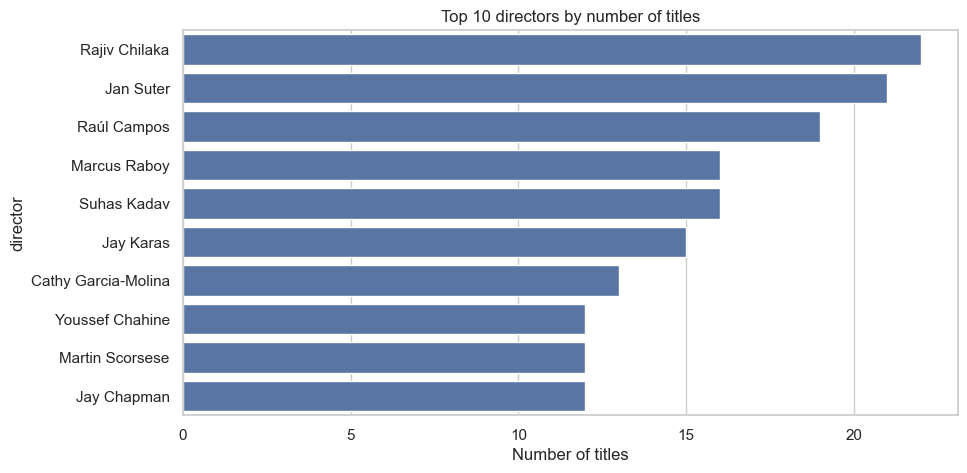

In [12]:
top_directors = directors["director"].value_counts().head(10)
plt.figure(figsize=(10, 5))
sns.barplot(x=top_directors.values, y=top_directors.index)
plt.title("Top 10 directors by number of titles")
plt.xlabel("Number of titles")
plt.savefig("outputs/09_top_directors.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.8 Content Duration

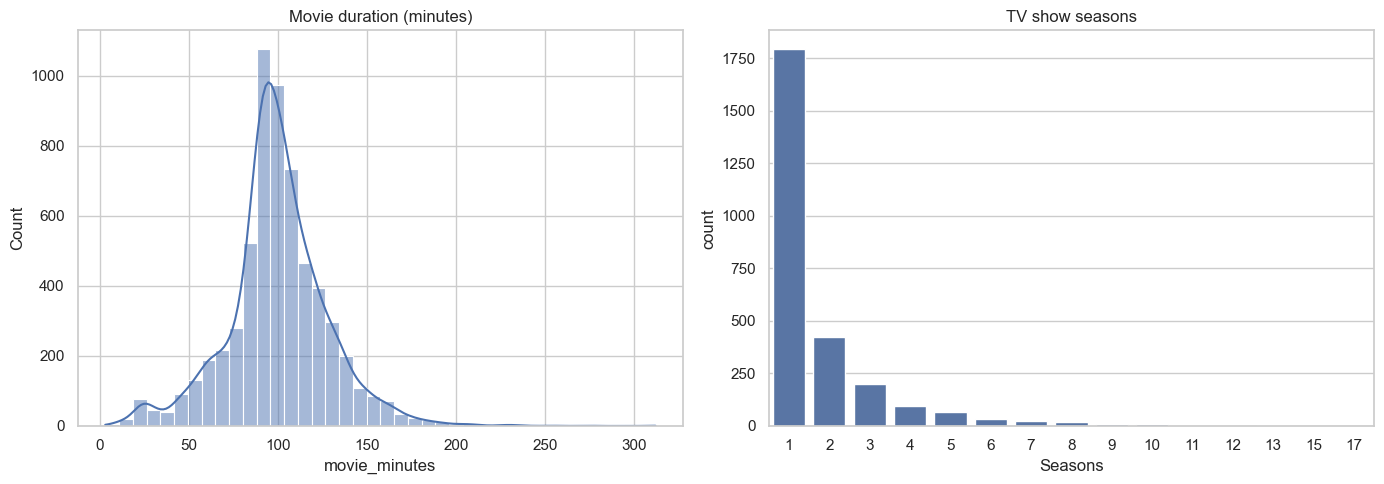

count    6131.0
mean       99.6
std        28.3
min         3.0
25%        87.0
50%        98.0
75%       114.0
max       312.0
Name: movie_minutes, dtype: float64
count    2676.0
mean        1.8
std         1.6
min         1.0
25%         1.0
50%         1.0
75%         2.0
max        17.0
Name: tv_seasons, dtype: float64


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(clean["movie_minutes"].dropna(), bins=40, ax=axes[0], kde=True)
axes[0].set_title("Movie duration (minutes)")
sns.countplot(x=clean["tv_seasons"].dropna().astype(int), ax=axes[1])
axes[1].set_title("TV show seasons")
axes[1].set_xlabel("Seasons")
plt.tight_layout()
plt.savefig("outputs/10_duration.png", dpi=150, bbox_inches="tight")
plt.show()

print(clean["movie_minutes"].describe().round(1))
print(clean["tv_seasons"].describe().round(1))

## 4. Statistical analysis


In [ ]:

ct = pd.crosstab(clean["type"], clean["audience"])
chi2, p, dof, _ = stats.chi2_contingency(ct)
print(f"Chi-square test (type vs audience): chi2={chi2:.2f}, dof={dof}, p-value={p:.4g}")
print("Significant association" if p < 0.05 else "No significant association", "at the 5% level\n")


m = clean.dropna(subset=["movie_minutes", "release_year"])
rho, p2 = stats.spearmanr(m["release_year"], m["movie_minutes"])
print(f"Spearman (release year vs movie minutes): rho={rho:.3f}, p-value={p2:.4g}\n")


recent = m[m["release_year"] >= 2015]["movie_minutes"]
older = m[m["release_year"] < 2015]["movie_minutes"]
u, p3 = stats.mannwhitneyu(recent, older)
print(f"Mann-Whitney U (movie length 2015+ vs older): U={u:.0f}, p-value={p3:.4g}")
print(f"Median minutes: 2015+ = {recent.median():.0f}, older = {older.median():.0f}")

Chi-square test (type vs audience): chi2=69.78, dof=3, p-value=4.764e-15
Significant association at the 5% level

Spearman (release year vs movie minutes): rho=-0.191, p-value=1.754e-51

Mann-Whitney U (movie length 2015+ vs older): U=3218494, p-value=7.365e-55
Median minutes: 2015+ = 96, older = 104




Three statistical tests were performed to examine relationships and differences in the Netflix dataset.

1. **Chi-Square Test:** The test showed a significant association between content type and audience category (chi-square = 69.78, p-value < 0.05). This indicates that audience categories are distributed differently across Movies and TV Shows.

2. **Spearman Correlation:** A weak negative correlation was observed between movie release year and duration (rho = -0.191, p-value < 0.05). This suggests that newer movies tend to have slightly shorter durations.

3. **Mann-Whitney U Test:** The test identified a significant difference in movie durations between recent and older movies (p-value < 0.05). Recent movies have a median duration of 96 minutes, compared to 104 minutes for older movies.

## 5.Netflix Dashboard

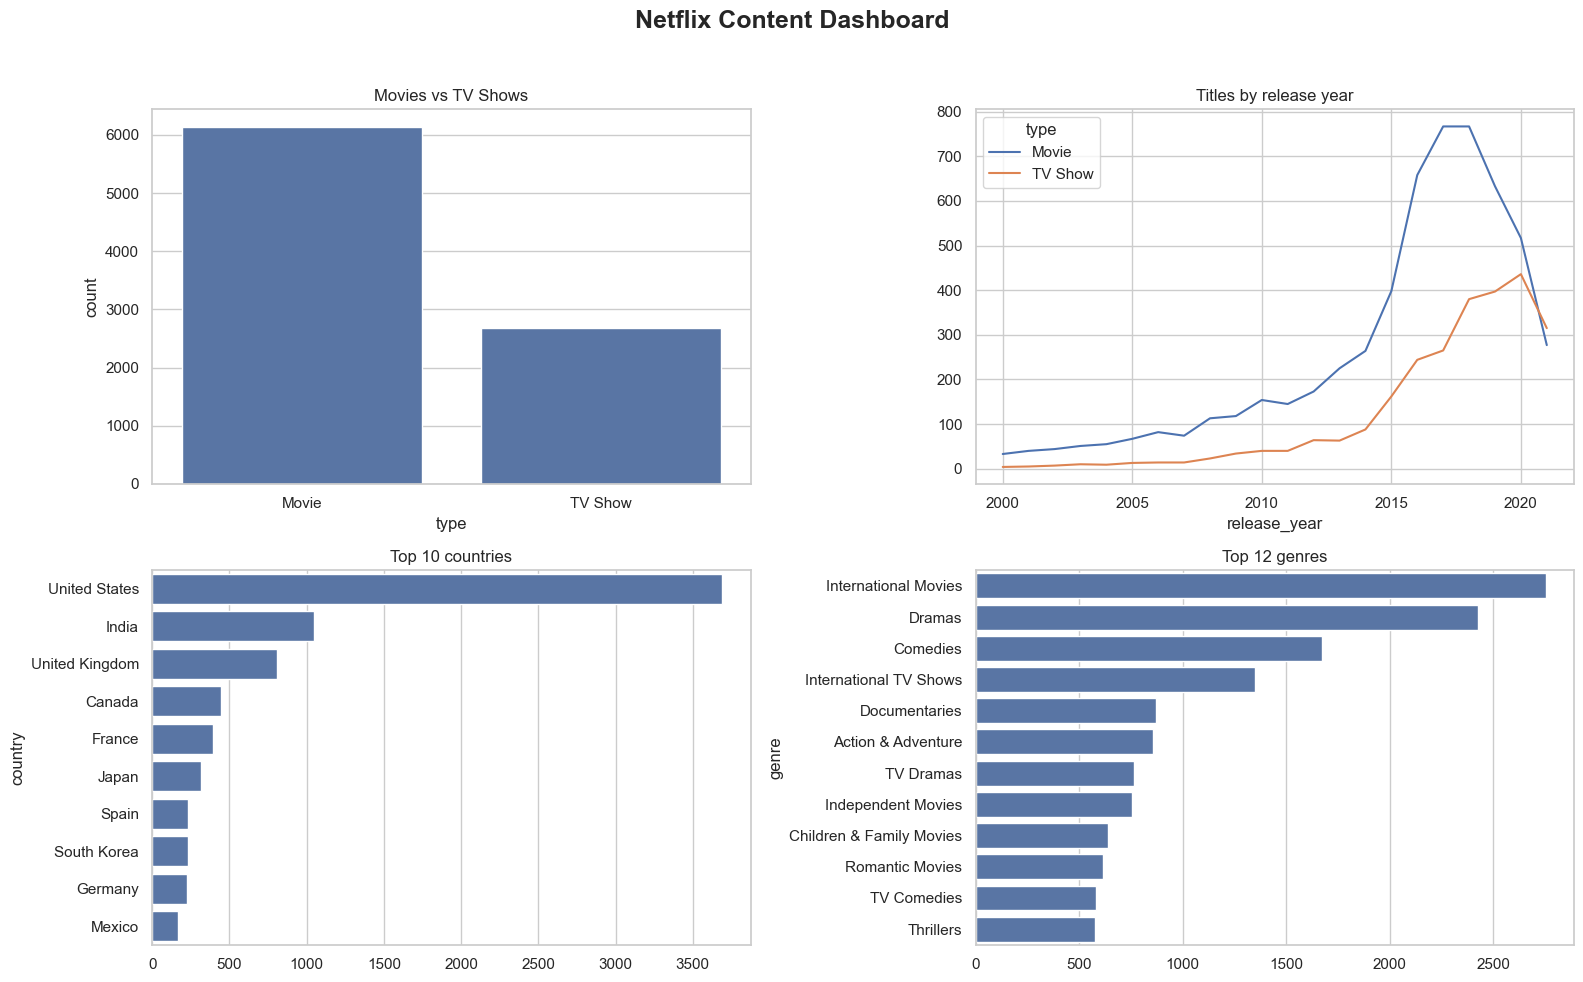

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle("Netflix Content Dashboard", fontsize=18, fontweight="bold")

sns.countplot(data=clean, x="type", ax=axes[0, 0])
axes[0, 0].set_title("Movies vs TV Shows")

by_year.plot(ax=axes[0, 1])
axes[0, 1].set_title("Titles by release year")

sns.barplot(x=top_countries.values, y=top_countries.index, ax=axes[1, 0])
axes[1, 0].set_title("Top 10 countries")

sns.barplot(x=top_genres.values, y=top_genres.index, ax=axes[1, 1])
axes[1, 1].set_title("Top 12 genres")

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("outputs/00_dashboard.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Key Findings

1. **Content Distribution:** Movies account for 69.6% (6,131 titles) of the Netflix catalogue, while TV Shows represent 30.4% (2,676 titles). This shows that Movies make up the majority of the available content.

2. **Country-wise Distribution:** The United States contributes the highest number of titles to the Netflix catalogue, followed by India and the United Kingdom. This highlights the significant contribution of these countries to Netflix's content library.

**3. Genre Analysis:** International Movies are the most frequently listed genre in the Netflix catalogue, followed by Dramas and Comedies. The trend analysis shows that International Movies and Dramas reached their highest counts around 2018, followed by a decline in subsequent years.

4. **Content Duration:** The average movie duration is 99.6 minutes, with a median of 98 minutes. For TV Shows, the average number of seasons is 1.8, while the median is one season. This indicates that most TV Shows in the dataset have only one season.

## 7. Project Limitations

1. The dataset represents a snapshot of Netflix's content catalogue and may not include its complete or latest collection.

2. Some records contain missing information, particularly in the director, cast and country columns. These missing values were labelled as "Unknown" during data cleaning.

3. The dataset does not contain viewer ratings, streaming numbers or audience engagement data. Therefore, the analysis cannot determine the actual popularity of individual titles.

4. Some titles are associated with multiple countries, genres or directors. These values were separated for analysis, which means a single title may be counted under multiple categories.